## Modern Portfolio Theory

Modern portfolio theory also popularly called Mean-Variance Portfolio Theory (MVP) is a major breakthrough in finance. It is based on the premise that returns are normally distributed and by looking at mean and variance, we can essentially describe the distribution of end-of-period wealth.

The basic idea of this theory is to achieve diversification by constructing a portfolio for a minimal portfolio risk or maximal portfolio returns. Accordingly, the Efficient Frontier is a set of optimal portfolios in the risk-return spectrum, and portfolios located under the Efficient Frontier curve are considered sub-optimal.

This means that the portfolios on the frontier offered

- Highest expected return for a given level of risk

- Lowest level of risk for a given level of expected returns

In essence, the investors' goal should be to select a level of risk that he/she is comfortable with and then find a portfolio that maximizes returns based on the selected risk level.

### import libraries

In [1]:
# data manipuation
import pandas as pd
import numpy as np

# data visualization
import matplotlib as mpl
import matplotlib.pyplot as plt

import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

# statistical analysis & optimizatio
import scipy.stats as scs
import scipy.optimize as sco

# scikit learn(sklearn) package is used primarily for machine learning
import sklearn

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf

# float display
pd.options.display.float_format = '{:0.4f}'.format

# operating system
import os

# Image package
from PIL import Image

# tabke formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

dir_path = r'C:\Admin\CQF Course\Python Labs\Portfolio Optimizaton'

### Retrive Data

In [2]:
assets = ['HDFCBANK', 'ITC', 'RELIANCE', 'TCS', 'ASIANPAINT']

assets.sort()
yahoo_tickers = [item + '.NS' for item in assets]

# Number of assets
num_asset = len(assets)

# Number of portfolio for optimization
num_portfolio = 5000

In [3]:
df = yf.download(tickers = yahoo_tickers, start='2015-01-01', end='2022-12-31', progress=False)['Adj Close']
df.columns = assets

### Visualize Time Series

We use cufflinks for interactive visualization. It is one of the most feature rich third-party wrapper around Plotly by Santos Jorge. It binds the power of plotly with the flexibility of pandas for easy plotting.

When you import cufflinks library, all pandas data frames and series objects have a new method .iplot() attached to them which is similar to pandas' built-in .plot() method.

In [4]:
df.loc['2022',:].normalize().iplot(title='Normalized Price Plot')                  # normalize()

In [5]:
# dataframe of returns and volatility

df_returns = df.pct_change().dropna()                                   # operation on whole df
df1 = pd.DataFrame({'Ann Ret' : df_returns.mean()*252*100,
                    'Ann Vol' : df_returns.std()*np.sqrt(252)*100})

df1.iplot(kind = 'barh', title = 'Annualized Return & Volatility (%)')

### Portfolio Statistics

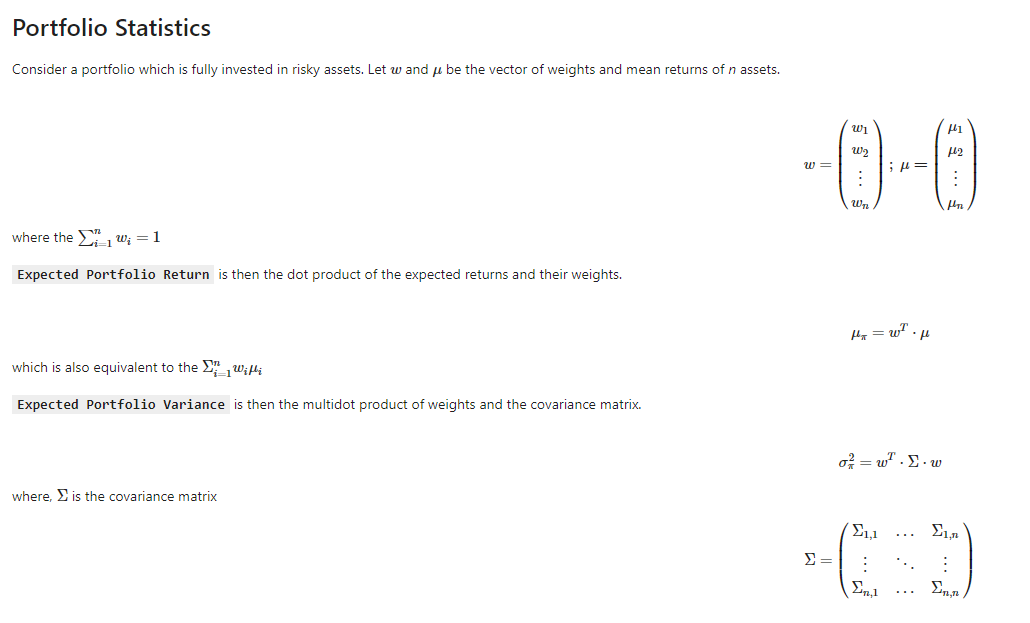

In [6]:
Image.open(os.path.join(dir_path,'portfolio_statistics.PNG'))

## Method 1- Monte Carlo Portfolio Simulation with Optimization

In [7]:
def portfolio_simulation(df_returns):
    
    rets = []
    vols =[]
    wts = [] 
    
    for i in range(num_portfolio):
        
        # simulate 5000 portfolios
        
        # random weights allocation
        # weight vector from np.random.random() : rank 1 array
        weights = np.random.random(num_asset)[:,np.newaxis]                          
        
        # Set weights such that sum of weights equals 1
        weights = weights/np.sum(weights)
        
        wts.append(weights.flatten())
        
        returns = np.array(df_returns.mean()*252)[:,np.newaxis]                 # return vector
        rets.append(np.linalg.multi_dot([weights.T,returns]))
        
        covar = df_returns.cov()*252                                            # covariance matrix
        vols.append(np.sqrt(np.linalg.multi_dot([weights.T,covar,weights])))
        
    # create daraframe for analysis
    df_port = pd.DataFrame({
        'port_rets': np.array(rets).flatten(),
        'port_vols':np.array(vols).flatten(),
        'port_weights' :wts
        })
    
    df_port['port_sharpe'] = df_port['port_rets']/df_port['port_vols']
        
    return df_port

### Maximize Sharpe Ratio

In [8]:
# Create a dataframe for analysis
df2 = portfolio_simulation(df_returns)

In [9]:
# Get the max sharpe portfolio stats
msr = df2.iloc[df2['port_sharpe'].idxmax(),:]
msrp_wts = df2.iloc[df2['port_sharpe'].idxmax(),2]   


msr,dict(zip(assets,msrp_wts))

(port_rets                                                  0.2160
 port_vols                                                  0.1804
 port_weights    [0.24909283103675167, 0.23367245506648263, 0.0...
 port_sharpe                                                1.1974
 Name: 869, dtype: object,
 {'ASIANPAINT': 0.24909283103675167,
  'HDFCBANK': 0.23367245506648263,
  'ITC': 0.02003018118625344,
  'RELIANCE': 0.28526178379395445,
  'TCS': 0.21194274891655793})

### Visulaize Simulated Portfolio

### Plotly Package

In [10]:
# Easy thinking-----------------------------------------------------------------------------------------------------------
# plotly.express(px) - similar to matplotlib.pyplot(plt)
# replace panda.plot ---> cufflinks(cf).iplot
# replace matplotlib.pyplot(plt) --> plotly.express(px)


# labels -nice way to label xlabel, ylabel and colorbar
# adding traces/layers to base plot --> add_scatter() or update()
# attributes - mode,marker,layout_showlegend,labels,color,title,


# px.scatter()
fig = px.scatter(data_frame = df2, x = 'port_vols', y = 'port_rets', color = 'port_sharpe',
                 labels={'port_vols': 'Expected Volatility', 'port_rets': 'Expected Return','port_sharpe': 'Sharpe Ratio'},
                 title='Monte Carlo Simulated Portfolio',)

# plot max share ratio portfolio
# add_scatter()
fig.add_scatter(mode = 'markers', x =[df2.iloc[df2['port_sharpe'].idxmax(),1]],
                y = [df2.iloc[df2['port_sharpe'].idxmax(),0]],
                marker = dict(color='RoyalBlue', size=20, symbol='star'),name = 'Max_Sharpe')


# add minimum variance portfolio
fig.add_scatter(mode = 'markers', x =[df2.iloc[df2['port_vols'].idxmin(),1]],
                y = [df2.iloc[df2['port_vols'].idxmin(),0]],
                marker = dict(color='Red', size=20, symbol='circle'),name = 'Min_Variance')


fig.update(layout_showlegend=False)                 # update()
fig.update_xaxes(showspikes=True)                   # update_xaxes()
fig.update_yaxes(showspikes=True)                   # update_yaxes()
fig.show()

## Method 2 - Efficient Frontier Creation with Optimization

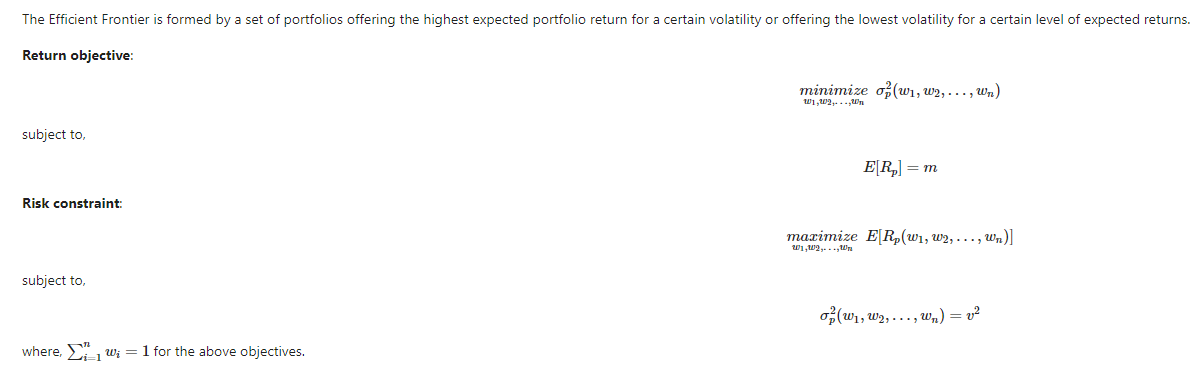

In [11]:
Image.open(os.path.join(dir_path,'efficient_frontier.PNG'))

We can use numerical optimization to achieve this objective. The goal of optimization is to find the optimal value of the objective function by adjusting the target variables operating withing some boundary conditions and constraints.

### Constrained Optimization

Construction of optimal portfolios is a constrained optimization problem where we specify some boundary conditions and constraints. The objective function here is a function returning maximum sharpe ratio, minimum variance (volatility) and the target variables are portfolio weights. We will use the minimize function from scipy optimization module to achieve our objective.

### Portfolio Statistics

In [12]:
def portolio_stats(weights):
    port_weights = np.array(weights)[:,np.newaxis]
    port_rets = np.linalg.multi_dot([port_weights.T,df_returns.mean()*252])[:,np.newaxis]          
    port_vols = np.sqrt(np.linalg.multi_dot([port_weights.T,df_returns.cov()*252,port_weights])) # gives ndarray (1,1)
    
    return np.array([port_rets,port_vols,port_rets/port_vols]).flatten()

def min_volatility(weights):
    return portolio_stats(weights)[1]

def min_variance(weights):
    return portolio_stats(weights)[1]**2

def max_sharpe_ratio(weights):
    return -portolio_stats(weights)[2]

In [13]:
# scipy optimize method only works for minimization and not for maximization, 
# scipy optimize works for equality constraints, make RHS as zero(preferred)
# 'to be optimized' params and initial values for params are given in list
# x in constrainst equation refers to 'to be optimized' param which is weight vector

# Specify constraints, bounds and initial weights
initial_wts = num_asset*[1/num_asset]
bounds = tuple((0,1) for x in range(num_asset))                # upper and lower bounds, since we have (5,1) array/column vector
cons ={'type':'eq','fun': lambda x: np.sum(x)-1}               # equality constraints, sum(weights) -1 = 0


In [14]:
# Optimizing for maximum sharpe ratio
optimize_sharpe = sco.minimize(fun = max_sharpe_ratio, x0= initial_wts, method='SLSQP', bounds=bounds, constraints=cons)

# parameters
optimize_sharpe['fun']
optimize_sharpe['x']


# Optimizing for minimum variance
optimize_var = sco.minimize(fun = min_variance, x0= initial_wts, method='SLSQP', bounds=bounds, constraints=cons)

In [15]:
target_rets = np.linspace(0.155,0.24,100)
target_vols = []

for tr in target_rets:
    ef_cons =({'type':'eq','fun': lambda x: np.sum(x)-1},
           {'type':'eq','fun': lambda x: portolio_stats(x)[0]-tr})
    
    optimize_ef = sco.minimize(fun = min_variance, x0= initial_wts, method='SLSQP', bounds=bounds, constraints=ef_cons)
    target_vols.append(optimize_ef['fun'])
    
target_vols = np.array(target_vols)

In [16]:
# create dataframe for efficient frontier portfolios
ef_port = pd.DataFrame({'target_rets':target_rets,
                       'target_vols':target_vols,
                       'target_sharpe':target_rets/target_vols})

In [17]:
# Plot efficient frontier portfolio

fig = px.scatter(data_frame = ef_port, x = 'target_vols', y = 'target_rets', color = 'target_sharpe',
                 labels={'port_vols': 'Expected Volatility', 'port_rets': 'Expected Return','port_sharpe': 'Sharpe Ratio'})

# add max sharpe ratio portfolio
fig.add_scatter(mode = 'markers', x =[ef_port.iloc[ef_port['target_sharpe'].idxmax(),1]],
                y = [ef_port.iloc[ef_port['target_sharpe'].idxmax(),0]],
                marker = dict(color='RoyalBlue', size=20, symbol='star'),name = 'Max_Sharpe')

# add minimum portfolio
fig.add_scatter(mode = 'markers', x =[ef_port.iloc[ef_port['target_vols'].idxmin(),1]],
                y = [ef_port.iloc[ef_port['target_vols'].idxmin(),0]],
                marker = dict(color='Red', size=20, symbol='circle'),name = 'Min_Variance')


fig.update(layout_showlegend=False)                
fig.update_xaxes(showspikes=True)                   
fig.update_yaxes(showspikes=True)                   
fig.show()

## References

[Numpy Linear Algenbra](https://numpy.org/doc/stable/reference/routines.linalg.html)

[Python Resources](https://github.com/kannansingaravelu/PythonResources)

[Scipy Optimization](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)

[Plotly Express Package](https://plotly.com/python/styling-plotly-express/)

[Yfinance Documentation](https://github.com/ranaroussi/yfinance)
